
# Phase 5 - Super-Clustering Contextual v5.3 (Pretrained Chronos, EURUSD)

Objetivo: replicar el pipeline `v5.2` en **EURUSD** para validar generalización en otra divisa.

Pipeline:
1. Construir ventanas de `move_pips` (len=32) desde segmentos EURUSD (phase4 v2).
2. Extraer embeddings con `amazon/chronos-t5-small` (`ChronosPipeline.embed`).
3. Selección de embedding/cantidad de clusters con walk-forward en train+val.
4. Clustering final y evaluación económica OOS en test.


DEVICE = cuda
MODEL_ID = amazon/chronos-t5-small
OUT_DIR = ./phases/phase05_context_sequencing/output_superclustering_contextual_EURUSD_v5_3_chronos_pretrained
windows = 1717
split counts: {'train': 1201, 'val': 258, 'test': 258}
non-null ret test: 258 / 258


chronos context length = 512


chronos_raw_clip -> (1717, 512)


chronos_zscore -> (1717, 512)


best embedding candidate = chronos_zscore
BEST_K = 9


,candidate,best_k,wf_score,eta2_wf_mean,kw_wf_mean
0,chronos_zscore,9,2.382019,0.101193,0.063747
1,chronos_raw_clip,9,1.657024,0.054735,0.259654


/tmp/ipykernel_233455/137626205.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_233455/137626205.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_233455/137626205.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `ne

/tmp/ipykernel_233455/137626205.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_233455/137626205.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f'ctx_emb_{j:03d}'] = Z[:, j]
/tmp/ipykernel_233455/137626205.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `ne

saved summary = ./phases/phase05_context_sequencing/output_superclustering_contextual_EURUSD_v5_3_chronos_pretrained/EURUSD_superclustering_summary_v5_3.json
test -> kw_p: 0.386254687340325 | anova_p: 0.2767715014150232 | eta2: 0.027258826038017915


,regime_id,n,mean_ret,median_ret,std_ret,t_like
0,2,52,8.852046,9.749830,109.072702,0.081157
1,1,42,-5.654976,-8.500814,72.302640,-0.078213
2,7,41,-7.065854,9.700060,79.069214,-0.089363
3,6,40,-17.142415,-19.400120,82.685668,-0.207320
4,4,34,28.379454,44.600368,92.764426,0.305930
5,3,24,-12.079130,-27.700067,84.777214,-0.142481
6,5,14,38.328639,60.299635,84.392927,0.454169
7,0,11,-44.399933,-50.600171,40.881950,-1.086052


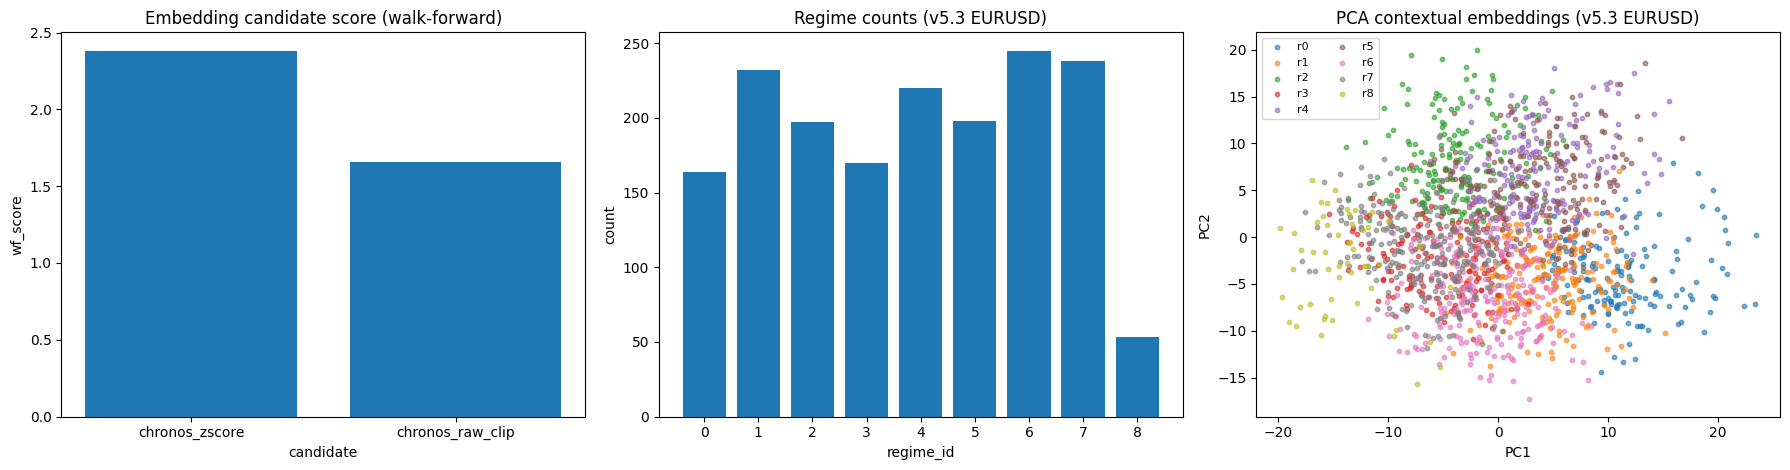

In [1]:

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from chronos import ChronosPipeline

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.stats import kruskal, f_oneway

pd.set_option('display.max_columns', 260)
pd.set_option('display.width', 340)

# =========================
# Config
# =========================
SYMBOL = 'EURUSD'
SEQ_LEN = 32
SEED = 42
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
MODEL_ID = 'amazon/chronos-t5-small'

TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

K_CANDIDATES = list(range(4, 13))
KMEANS_SEEDS = [11, 42, 77]
N_INIT_KMEANS = 50
MIN_CLUSTER_N_FOLD = 15
MIN_CLUSTER_N_TEST = 20

FOLD_SPECS = [
    (0.50, 0.10),
    (0.60, 0.10),
    (0.70, 0.10),
    (0.80, 0.10),
]

BATCH_EMB = 128
HORIZON_HOURS = 24

ROOT = Path('./phases/phase05_context_sequencing')
SEG_PATH = Path('./phases/phase04_transfer_clustering/output_transfer_EURUSD_full_v2/EURUSD_segment_cluster_assignments.parquet')
PRICE_PATH = Path('./data/Dataset_H1_v1/parquet_h1/EURUSD.parquet')

OUT_DIR = ROOT / 'output_superclustering_contextual_EURUSD_v5_3_chronos_pretrained'
OUT_DIR.mkdir(parents=True, exist_ok=True)

CAND_SEL_CSV = OUT_DIR / 'EURUSD_pretrained_embedding_candidates_v5_3.csv'
K_SEL_CSV = OUT_DIR / 'EURUSD_k_selection_walkforward_v5_3.csv'
EMB_PQ = OUT_DIR / 'EURUSD_context_window_embeddings_v5_3.parquet'
EMB_CSV = OUT_DIR / 'EURUSD_context_window_embeddings_v5_3.csv'
PROFILE_CSV = OUT_DIR / 'EURUSD_context_regime_profile_v5_3.csv'
TRANS_CSV = OUT_DIR / 'EURUSD_context_regime_transition_matrix_v5_3.csv'
SUMMARY_JSON = OUT_DIR / 'EURUSD_superclustering_summary_v5_3.json'

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def temporal_split(n: int, train_ratio: float, val_ratio: float):
    tr_end = int(n * train_ratio)
    va_end = int(n * (train_ratio + val_ratio))
    tr_end = max(1, min(tr_end, n - 2))
    va_end = max(tr_end + 1, min(va_end, n - 1))
    idx_train = np.arange(0, tr_end)
    idx_val = np.arange(tr_end, va_end)
    idx_test = np.arange(va_end, n)
    return idx_train, idx_val, idx_test


def pip_size(symbol: str) -> float:
    return 0.01 if str(symbol).upper().endswith('JPY') else 0.0001


def compute_forward_pips(df_price: pd.DataFrame, ts_vec: pd.Series, symbol: str, horizon_hours: int = 24):
    idx = df_price['timestamp'].to_numpy(dtype='datetime64[ns]')
    close = df_price['close'].to_numpy(dtype=float)
    ts = pd.to_datetime(ts_vec, errors='coerce').to_numpy(dtype='datetime64[ns]')
    pos = np.searchsorted(idx, ts, side='left')
    out = np.full(len(ts), np.nan, dtype=float)
    ps = pip_size(symbol)
    for i in range(len(ts)):
        p0 = pos[i]
        p1 = p0 + int(horizon_hours)
        if p0 < 0 or p1 >= len(idx):
            continue
        if idx[p0] != ts[i]:
            continue
        out[i] = (close[p1] - close[p0]) / ps
    return out


def zcol(s):
    s = pd.to_numeric(s, errors='coerce')
    m = float(s.mean())
    sd = float(s.std(ddof=0))
    if not np.isfinite(sd) or sd < 1e-9:
        return pd.Series(np.zeros(len(s)), index=s.index, dtype=float)
    return (s - m) / (sd + 1e-9)


print('DEVICE =', DEVICE)
print('MODEL_ID =', MODEL_ID)
print('OUT_DIR =', OUT_DIR)

# =========================
# Load metadata / build windows
# =========================
seg = pd.read_parquet(SEG_PATH).copy()
seg['start_ts'] = pd.to_datetime(seg['start_ts'], errors='coerce')
seg = seg.sort_values(['start_ts', 'global_segment_id']).reset_index(drop=True)
seg['move_pips'] = pd.to_numeric(seg['move_pips'], errors='coerce').fillna(0.0).astype(float)

rows = []
moves = seg['move_pips'].to_numpy(dtype=float)
starts = seg['start_ts'].to_numpy(dtype='datetime64[ns]')
for i in range(0, len(seg) - SEQ_LEN + 1):
    rows.append({
        'window_id': int(i),
        'start_ts': pd.Timestamp(starts[i]),
        'end_ts': pd.Timestamp(starts[i + SEQ_LEN - 1]),
        'move_seq': moves[i:i+SEQ_LEN].astype(np.float32),
    })

M = pd.DataFrame(rows).sort_values('window_id').reset_index(drop=True)
print('windows =', len(M))

# temporal split
idx_tr, idx_va, idx_te = temporal_split(len(M), TRAIN_RATIO, VAL_RATIO)
split = np.array(['train'] * len(M), dtype=object)
split[idx_va] = 'val'
split[idx_te] = 'test'
M['split'] = split

# forward returns
PX = pd.read_parquet(PRICE_PATH, columns=['timestamp', 'close']).copy()
PX['timestamp'] = pd.to_datetime(PX['timestamp'], errors='coerce')
PX['close'] = pd.to_numeric(PX['close'], errors='coerce')
PX = PX.dropna().sort_values('timestamp').drop_duplicates('timestamp', keep='last').reset_index(drop=True)

M['ret_fwd_24h_pips'] = compute_forward_pips(PX, M['end_ts'], symbol=SYMBOL, horizon_hours=HORIZON_HOURS)

idx_tv = np.concatenate([idx_tr, idx_va])
ret = pd.to_numeric(M['ret_fwd_24h_pips'], errors='coerce').to_numpy(dtype=float)

print('split counts:', M['split'].value_counts().to_dict())
print('non-null ret test:', int(np.isfinite(ret[idx_te]).sum()), '/', len(idx_te))

# =========================
# Pretrained Chronos embeddings
# =========================
pipe = ChronosPipeline.from_pretrained(
    MODEL_ID,
    device_map='cuda' if DEVICE == 'cuda' else 'cpu',
)
print('chronos context length =', pipe.model_context_length)

X_raw = np.vstack(M['move_seq'].to_numpy())  # [N, L]
a = X_raw[idx_tr].reshape(-1)
clip_lo = np.quantile(a, 0.01)
clip_hi = np.quantile(a, 0.99)
X_clip = np.clip(X_raw, clip_lo, clip_hi)

X_a = X_clip.astype(np.float32)  # raw clipped
mu = X_clip.mean(axis=1, keepdims=True)
sd = X_clip.std(axis=1, keepdims=True)
X_b = ((X_clip - mu) / (sd + 1e-6)).astype(np.float32)  # per-window zscore

candidates = {
    'chronos_raw_clip': X_a,
    'chronos_zscore': X_b,
}

@torch.no_grad()
def chronos_embed_matrix(X: np.ndarray, batch_size: int = 128):
    embs = []
    for i in range(0, len(X), batch_size):
        xb = torch.tensor(X[i:i+batch_size], dtype=torch.float32)  # CPU input avoids device mismatch in tokenizer
        h, _ = pipe.embed(xb)
        z = h[:, 1:, :].mean(dim=1)  # mean pool temporal tokens
        embs.append(z.detach().cpu().numpy().astype(np.float32))
    return np.vstack(embs)

emb_map = {}
for name, X in candidates.items():
    Z = chronos_embed_matrix(X, batch_size=BATCH_EMB)
    emb_map[name] = Z
    print(name, '->', Z.shape)

# =========================
# Walk-forward evaluation
# =========================
def build_folds(idx_tv):
    n = len(idx_tv)
    folds = []
    for tr_r, va_r in FOLD_SPECS:
        tr_end = int(n * tr_r)
        va_end = min(n, int(n * (tr_r + va_r)))
        if va_end - tr_end < 30:
            continue
        folds.append((idx_tv[:tr_end], idx_tv[tr_end:va_end]))
    return folds


def evaluate_k_walkforward(Z: np.ndarray, ret: np.ndarray, idx_tv: np.ndarray):
    folds = build_folds(idx_tv)
    rows = []
    for k in K_CANDIDATES:
        fold_eta2, fold_kw, fold_sil, fold_ch, fold_db, fold_ari = [], [], [], [], [], []

        for tr_idx, va_idx in folds:
            sc = StandardScaler()
            Ztr = sc.fit_transform(Z[tr_idx])
            Zva = sc.transform(Z[va_idx])

            seed_labels = {}
            sils, chs, dbs = [], [], []
            for sd in KMEANS_SEEDS:
                km = KMeans(n_clusters=k, n_init=N_INIT_KMEANS, random_state=sd)
                km.fit(Ztr)
                lv = km.predict(Zva)
                seed_labels[sd] = lv
                if len(np.unique(lv)) >= 2 and len(lv) > k:
                    sils.append(float(silhouette_score(Zva, lv)))
                    chs.append(float(calinski_harabasz_score(Zva, lv)))
                    dbs.append(float(davies_bouldin_score(Zva, lv)))

            aris = []
            keys = list(seed_labels.keys())
            for i in range(len(keys)):
                for j in range(i + 1, len(keys)):
                    aris.append(float(adjusted_rand_score(seed_labels[keys[i]], seed_labels[keys[j]])))

            lv = seed_labels[42]
            rv = ret[va_idx]
            ok = np.isfinite(rv)
            rv, lv = rv[ok], lv[ok]

            groups = []
            for cid in np.unique(lv):
                g = rv[lv == cid]
                if len(g) >= MIN_CLUSTER_N_FOLD:
                    groups.append(g)

            if len(groups) >= 2:
                kw = float(kruskal(*groups).pvalue)
                all_vals = np.concatenate(groups)
                gm = np.mean(all_vals)
                ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
                sst = np.sum((all_vals - gm) ** 2)
                eta2 = float(ssb / sst) if sst > 0 else np.nan
                fold_kw.append(kw)
                fold_eta2.append(eta2)

            if sils:
                fold_sil.append(float(np.mean(sils)))
            if chs:
                fold_ch.append(float(np.mean(chs)))
            if dbs:
                fold_db.append(float(np.mean(dbs)))
            if aris:
                fold_ari.append(float(np.mean(aris)))

        rows.append({
            'k': int(k),
            'folds_used': int(len(fold_eta2)),
            'eta2_wf_mean': float(np.nanmean(fold_eta2)) if fold_eta2 else np.nan,
            'eta2_wf_median': float(np.nanmedian(fold_eta2)) if fold_eta2 else np.nan,
            'kw_wf_mean': float(np.nanmean(fold_kw)) if fold_kw else np.nan,
            'sil_wf_mean': float(np.nanmean(fold_sil)) if fold_sil else np.nan,
            'ch_wf_mean': float(np.nanmean(fold_ch)) if fold_ch else np.nan,
            'db_wf_mean': float(np.nanmean(fold_db)) if fold_db else np.nan,
            'ari_wf_mean': float(np.nanmean(fold_ari)) if fold_ari else np.nan,
        })

    SEL = pd.DataFrame(rows)
    SEL['z_eta'] = zcol(SEL['eta2_wf_mean'])
    SEL['z_sil'] = zcol(SEL['sil_wf_mean'])
    SEL['z_ch'] = zcol(SEL['ch_wf_mean'])
    SEL['z_db'] = zcol(SEL['db_wf_mean'])
    SEL['z_ari'] = zcol(SEL['ari_wf_mean'])
    SEL['wf_score'] = 1.40*SEL['z_eta'] + 0.35*SEL['z_sil'] + 0.20*SEL['z_ch'] - 0.25*SEL['z_db'] + 0.20*SEL['z_ari']
    SEL = SEL.sort_values('wf_score', ascending=False).reset_index(drop=True)
    return SEL


def final_test_profile(Z: np.ndarray, best_k: int):
    sc = StandardScaler()
    Z_tv = sc.fit_transform(Z[idx_tv])
    Z_all = sc.transform(Z)

    km = KMeans(n_clusters=best_k, n_init=N_INIT_KMEANS, random_state=SEED)
    km.fit(Z_tv)
    reg = km.predict(Z_all)
    dist = km.transform(Z_all).min(axis=1)

    out = M[['window_id', 'start_ts', 'end_ts', 'split', 'ret_fwd_24h_pips']].copy()
    out['symbol'] = SYMBOL
    out['regime_id'] = reg.astype(int)
    out['regime_dist'] = dist.astype(float)
    out['regime_token'] = out['regime_id'].map(lambda x: f'r{x:02d}')

    for j in range(Z.shape[1]):
        out[f'ctx_emb_{j:03d}'] = Z[:, j]

    test_df = out[out['split'] == 'test'].copy()
    prof = (test_df.groupby('regime_id')['ret_fwd_24h_pips']
            .agg(n='count', mean_ret='mean', median_ret='median', std_ret='std')
            .reset_index())
    prof['t_like'] = prof['mean_ret'] / prof['std_ret'].replace(0, np.nan)
    prof = prof.sort_values('n', ascending=False).reset_index(drop=True)

    groups = []
    for _, g in test_df.groupby('regime_id'):
        x = pd.to_numeric(g['ret_fwd_24h_pips'], errors='coerce').dropna().to_numpy()
        if len(x) >= MIN_CLUSTER_N_TEST:
            groups.append(x)

    kw_p, anova_p, eta2 = np.nan, np.nan, np.nan
    if len(groups) >= 2:
        kw_p = float(kruskal(*groups).pvalue)
        anova_p = float(f_oneway(*groups).pvalue)
        all_vals = np.concatenate(groups)
        gm = np.mean(all_vals)
        ssb = sum(len(g) * (np.mean(g) - gm) ** 2 for g in groups)
        sst = np.sum((all_vals - gm) ** 2)
        eta2 = float(ssb / sst) if sst > 0 else np.nan

    tr = pd.crosstab(out['regime_token'], out['regime_token'].shift(-1)).fillna(0)
    tr_prob = tr.div(tr.sum(axis=1), axis=0).fillna(0.0)

    return out, prof, tr_prob, kw_p, anova_p, eta2

# candidate selection
cand_rows, sel_by_candidate = [], {}
for name, Z in emb_map.items():
    SEL = evaluate_k_walkforward(Z=Z, ret=ret, idx_tv=idx_tv)
    sel_by_candidate[name] = SEL
    top = SEL.iloc[0]
    cand_rows.append({
        'candidate': name,
        'best_k': int(top['k']),
        'wf_score': float(top['wf_score']),
        'eta2_wf_mean': None if not np.isfinite(top['eta2_wf_mean']) else float(top['eta2_wf_mean']),
        'kw_wf_mean': None if not np.isfinite(top['kw_wf_mean']) else float(top['kw_wf_mean']),
    })

CANDS = pd.DataFrame(cand_rows).sort_values('wf_score', ascending=False).reset_index(drop=True)
CANDS.to_csv(CAND_SEL_CSV, index=False)

best_candidate = str(CANDS.iloc[0]['candidate'])
BEST_K = int(CANDS.iloc[0]['best_k'])
SEL_BEST = sel_by_candidate[best_candidate].copy()
SEL_BEST.to_csv(K_SEL_CSV, index=False)

print('best embedding candidate =', best_candidate)
print('BEST_K =', BEST_K)
display(CANDS)

# final evaluation
Z_best = emb_map[best_candidate]
out, prof, tr_prob, kw_p, anova_p, eta2 = final_test_profile(Z_best, BEST_K)

out.to_parquet(EMB_PQ, index=False)
out.to_csv(EMB_CSV, index=False)
prof.to_csv(PROFILE_CSV, index=False)
tr_prob.to_csv(TRANS_CSV)

summary = {
    'symbol': SYMBOL,
    'model_tag': 'v5_3_chronos_pretrained',
    'pretrained_model': MODEL_ID,
    'embedding_candidate': best_candidate,
    'n_windows': int(len(out)),
    'split_counts': {k: int(v) for k, v in out['split'].value_counts().to_dict().items()},
    'best_k': int(BEST_K),
    'kw_pvalue_test': None if not np.isfinite(kw_p) else float(kw_p),
    'anova_pvalue_test': None if not np.isfinite(anova_p) else float(anova_p),
    'eta2_test': None if not np.isfinite(eta2) else float(eta2),
    'wf_score_best_k': float(SEL_BEST.iloc[0]['wf_score']),
    'eta2_wf_mean_best_k': None if not np.isfinite(SEL_BEST.iloc[0]['eta2_wf_mean']) else float(SEL_BEST.iloc[0]['eta2_wf_mean']),
}
SUMMARY_JSON.write_text(json.dumps(summary, indent=2))

print('saved summary =', SUMMARY_JSON)
print('test -> kw_p:', kw_p, '| anova_p:', anova_p, '| eta2:', eta2)
display(prof)

# diagnostics
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

axes[0].bar(CANDS['candidate'], CANDS['wf_score'])
axes[0].set_title('Embedding candidate score (walk-forward)')
axes[0].set_xlabel('candidate')
axes[0].set_ylabel('wf_score')

cnt = out['regime_id'].value_counts().sort_index()
axes[1].bar(cnt.index.astype(str), cnt.values)
axes[1].set_title('Regime counts (v5.3 EURUSD)')
axes[1].set_xlabel('regime_id')
axes[1].set_ylabel('count')

xy = PCA(n_components=2, random_state=SEED).fit_transform(StandardScaler().fit_transform(Z_best))
for rid in sorted(np.unique(out['regime_id'])):
    m = out['regime_id'].to_numpy() == rid
    axes[2].scatter(xy[m, 0], xy[m, 1], s=10, alpha=0.6, label=f'r{rid}')
axes[2].set_title('PCA contextual embeddings (v5.3 EURUSD)')
axes[2].set_xlabel('PC1')
axes[2].set_ylabel('PC2')
axes[2].legend(ncol=2, fontsize=8)

plt.tight_layout()
plt.show()
